# 01 · Flight cleaning and EDA

**Executed on real inputs on 19 October 2026: 22 code cells, 13 figures, no errors.**

Study: ATL, ORD and DFW departure delays of at least 15 minutes at a simulated two-hour cutoff.

| Period | Role |
|---|---|
| November–December 2024 | Historical context only |
| January–September 2025 | Initial training and exploratory analysis |
| October–December 2025 | Validation for later model/settings selection |
| January–December 2025 | Final refit after selection |
| January–March 2026 | Reserved final test |

This notebook reads original raw sources, applies the declared label rules and saves one clean Parquet plus the shared manifest. Outcome plots use initial training only. Loading test labels for fixed preparation rules is not permission to explore or tune against them. Aircraft rotation is excluded.

Follow the six EDA stages below. Tables and plots stay inline. [Teacher-reference methodology](../reports/REFERENCE_EDA_REVIEW.md) · [EDA plan](../EDA_PLAN.md).


In [1]:
from pathlib import Path
import json
import site
if site.ENABLE_USER_SITE:
    site.addsitedir(site.getusersitepackages())
import platform
from datetime import datetime, timezone

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import PercentFormatter
import seaborn as sns


def show_table(data, **kwargs):
    print(data.to_string(**kwargs))

def show_plot():
    plt.tight_layout()
    plt.show()

ROOT = Path.cwd().resolve()
if ROOT.name == 'notebooks':
    ROOT = ROOT.parent
if (ROOT / 'departure-delay-classification/config/project.json').is_file():
    ROOT = ROOT / 'departure-delay-classification'
if not (ROOT / 'config/project.json').is_file():
    raise FileNotFoundError('Open this notebook inside departure-delay-classification.')
RAW = ROOT / 'data/raw'
CONFIG = json.loads((ROOT / 'config/project.json').read_text())
ORIGINS = CONFIG['scope']['origin_airports']
SEED = CONFIG['sampling']['seed']
WRITE_OUTPUTS = True
PLOT_SAMPLE_SIZE = 10_000
sns.set_theme(style='whitegrid', context='notebook', palette=['#247BA0', '#E08D3C', '#5C946E'])
plt.rcParams.update({'figure.dpi': 110, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.max_columns', 35)

show_table(pd.Series({'project_root': str(ROOT), 'python': platform.python_version(),
                   'pandas': pd.__version__, 'exploratory_period': CONFIG['split']['train_start'] + ' to ' + CONFIG['split']['train_end'],
                   'output_mode': 'one clean Parquet + shared JSON manifest'}).to_frame('setting'))


                                                                                         setting
project_root        /Users/aaditrangnekar/Desktop/ML & DW Project/departure-delay-classification
python                                                                                    3.13.6
pandas                                                                                     3.0.3
exploratory_period                                                      2025-01-01 to 2025-09-30
output_mode                                             one clean Parquet + shared JSON manifest


## 0. Source audit and parsing

Read the project's raw BTS files in chunks, retaining the three origins. Preserve source-row IDs and check file coverage, types and repeated schedule identities.


In [2]:
SOURCE_COLUMNS = {
    'FlightDate': 'flight_date', 'Reporting_Airline': 'airline',
    'Flight_Number_Reporting_Airline': 'flight_number', 'Origin': 'origin', 'Dest': 'destination',
    'CRSDepTime': 'scheduled_departure_hhmm', 'CRSElapsedTime': 'scheduled_duration_minutes',
    'Distance': 'distance_miles', 'DepDelay': 'departure_delay_minutes',
    'DepDel15': 'departure_delay_15_source', 'Cancelled': 'cancelled', 'Diverted': 'diverted',
}
source_paths = sorted((RAW / 'flights/bts/2024_context/csv').glob('2024_*.csv'))
source_paths += sorted((RAW / 'flights/bts/2025/csv').glob('2025_*.csv'))
source_paths += sorted((RAW / 'flights/bts/2026/csv').glob('2026_0[123].csv'))
expected_months = pd.period_range('2024-11', '2026-03', freq='M').strftime('%Y_%m').tolist()
assert [p.stem for p in source_paths] == expected_months, 'Missing or unexpected source months.'
parts, source_log = [], []
for path in source_paths:
    all_count = scope_count = 0
    for chunk in pd.read_csv(path, usecols=list(SOURCE_COLUMNS), dtype='string', chunksize=150_000):
        all_count += len(chunk)
        subset = chunk.loc[chunk['Origin'].str.strip().isin(ORIGINS)].copy()
        scope_count += len(subset)
        subset['source_row_number'] = subset.index.to_numpy() + 2  # header is CSV row 1
        subset['source_file'] = path.relative_to(ROOT).as_posix()
        subset['flight_id'] = path.stem + ':' + subset['source_row_number'].astype(str)
        parts.append(subset.rename(columns=SOURCE_COLUMNS))
    source_log.append({'source_file': path.relative_to(ROOT).as_posix(),
                       'national_rows_read': all_count, 'three_origin_rows': scope_count})
    print(f'{path.stem}: read {all_count:,}; retained {scope_count:,} scheduled rows.')

flights = pd.concat(parts, ignore_index=True)
del parts
assert flights['flight_id'].is_unique
show_table(pd.DataFrame(source_log))
show_table(flights.head(5))


2024_11: read 575,404; retained 75,647 scheduled rows.


2024_12: read 590,581; retained 77,496 scheduled rows.


2025_01: read 539,747; retained 70,648 scheduled rows.


2025_02: read 504,884; retained 65,498 scheduled rows.


2025_03: read 600,872; retained 78,143 scheduled rows.


...

2025_11: read 570,550; retained 79,623 scheduled rows.


2025_12: read 582,304; retained 79,324 scheduled rows.


2026_01: read 544,003; retained 73,955 scheduled rows.


2026_02: read 515,037; retained 70,581 scheduled rows.


2026_03: read 612,102; retained 84,050 scheduled rows.
                                          source_file  national_rows_read  three_origin_rows
0   data/raw/flights/bts/2024_context/csv/2024_11.csv              575404              75647
1   data/raw/flights/bts/2024_context/csv/2024_12.csv              590581              77496
2           data/raw/flights/bts/2025/csv/2025_01.csv              539747              70648
3           data/raw/flights/bts/2025/csv/2025_02.csv              504884              65498
4           data/raw/flights/bts/2025/csv/2025_03.csv              600872              78143
5           data/raw/flights/bts/2025/csv/2025_04.csv              583950              77315
6           data/raw/flights/bts/2025/csv/2025_05.csv              605648              82443
7           data/raw/flights/bts/2025/csv/2025_06.csv              611575              85593
8           data/raw/flights/bts/2025/csv/2025_07.csv              631428              88013
9           dat

In [3]:
text_columns = ['airline', 'flight_number', 'origin', 'destination']
for column in text_columns:
    flights[column] = flights[column].str.strip().replace('', pd.NA)
flights['flight_date'] = pd.to_datetime(flights['flight_date'], format='%Y-%m-%d', errors='coerce')
numeric_columns = ['scheduled_departure_hhmm', 'scheduled_duration_minutes', 'distance_miles',
                   'departure_delay_minutes', 'departure_delay_15_source', 'cancelled', 'diverted']
parse_log = []
for column in numeric_columns:
    original = flights[column]
    numeric = pd.to_numeric(original, errors='coerce').astype('float64')
    parse_log.append({'variable': column,
                      'nonmissing_unparseable': int((original.notna() & numeric.isna()).sum()),
                      'nonfinite': int((numeric.notna() & ~np.isfinite(numeric)).sum())})
    flights[column] = numeric.where(np.isfinite(numeric))
show_table(pd.DataFrame(parse_log))

bad_status = ~flights['cancelled'].isin([0, 1])
if bad_status.any():
    show_table(flights.loc[bad_status].head(10))
    raise ValueError('Cancellation status is unresolved. Clarify these records before proceeding.')

# This flag is an audit/population rule, never a model predictor.
flights['label_eligible'] = flights['cancelled'].eq(0) & flights['departure_delay_minutes'].notna()
flights['delayed_departure'] = flights['departure_delay_minutes'].ge(15).where(flights['label_eligible']).astype('Int8')
reconcile = flights['label_eligible'] & flights['departure_delay_15_source'].notna()
label_mismatch = reconcile & flights['departure_delay_15_source'].ne(flights['delayed_departure'])
if label_mismatch.fillna(False).any():
    show_table(flights.loc[label_mismatch.fillna(False)].head(10))
    raise ValueError('DepDelay and source DepDel15 disagree; investigate before choosing a label.')

flights['split'] = 'context'
for split_name in ['train', 'validation', 'test']:
    in_period = flights['flight_date'].between(
        CONFIG['split'][split_name + '_start'], CONFIG['split'][split_name + '_end'])
    flights.loc[in_period, 'split'] = split_name
study = flights['split'].isin(['train', 'validation', 'test'])
development = flights['split'].isin(['train', 'validation'])

identity = ['flight_date', 'airline', 'flight_number', 'origin', 'destination', 'scheduled_departure_hhmm']
duplicate_identity = flights.duplicated(identity, keep=False)
if duplicate_identity.any():
    show_table(flights.loc[duplicate_identity, ['flight_id', *identity, 'departure_delay_minutes', 'cancelled']].head(20))
    raise ValueError('Repeated schedule identities require review. No duplicate flights were automatically deleted.')


                     variable  nonmissing_unparseable  nonfinite
0    scheduled_departure_hhmm                       0          0
1  scheduled_duration_minutes                       0          0
2              distance_miles                       0          0
3     departure_delay_minutes                       0          0
4   departure_delay_15_source                       0          0
5                   cancelled                       0          0
6                    diverted                       0          0


### Timezones and valid query timestamps

Rebuild mappings from raw station/airport references and convert local scheduled times to UTC. Invalid clocks, 2400 or unresolved DST times stop for clarification.


In [4]:
network_by_origin = {'ATL': 'GA_ASOS', 'ORD': 'IL_ASOS', 'DFW': 'TX_ASOS'}
timezone_by_origin = {}
for origin, network in network_by_origin.items():
    payload = json.loads((RAW / f'weather/stations/{network}.geojson').read_text())
    hits = [f['properties'] for f in payload['features'] if f['properties'].get('sid') == origin]
    assert len(hits) == 1 and hits[0].get('tzname'), f'Unresolved timezone for {origin}'
    timezone_by_origin[origin] = hits[0]['tzname']
airport_reference = pd.read_csv(RAW / 'reference/airports/airports.csv',
    usecols=['iata_code', 'name', 'latitude_deg', 'longitude_deg'], dtype={'iata_code': 'string'})
origin_reference = airport_reference.loc[airport_reference['iata_code'].isin(ORIGINS)].copy()
assert origin_reference['iata_code'].is_unique and len(origin_reference) == len(ORIGINS)
origin_reference['timezone'] = origin_reference['iata_code'].map(timezone_by_origin)
show_table(origin_reference)

clock = flights['scheduled_departure_hhmm']
valid_clock = clock.notna() & clock.mod(1).eq(0) & clock.ge(0) & clock.lt(2400) & clock.mod(100).lt(60)
required_keys = ['flight_date', 'airline', 'flight_number', 'origin', 'destination']
bad_required = flights[required_keys].isna().any(axis=1) | ~valid_clock
if bad_required.any():
    show_table(flights.loc[bad_required, ['flight_id', *required_keys, 'scheduled_departure_hhmm']].head(20))
    raise ValueError('Required identity/date/clock values need clarification, including any 2400 records.')

flights['scheduled_departure_minutes'] = (clock // 100 * 60 + clock % 100).astype('int16')
local_naive = flights['flight_date'] + pd.to_timedelta(flights['scheduled_departure_minutes'], unit='m')
scheduled_utc = pd.Series(pd.NaT, index=flights.index, dtype='datetime64[ns, UTC]')
for origin, tz in timezone_by_origin.items():
    indices = flights.index[flights['origin'].eq(origin)]
    localized = local_naive.loc[indices].dt.tz_localize(tz, ambiguous='NaT', nonexistent='NaT')
    scheduled_utc.loc[indices] = localized.dt.tz_convert('UTC')
if scheduled_utc.isna().any():
    show_table(flights.loc[scheduled_utc.isna(), ['flight_id', 'flight_date', 'origin', 'scheduled_departure_hhmm']].head(20))
    raise ValueError('Unresolved DST/local-time records: clarify before deleting or assigning an offset.')
flights['scheduled_departure_utc'] = scheduled_utc
flights['prediction_cutoff_utc'] = scheduled_utc - pd.Timedelta(minutes=CONFIG['scope']['prediction_horizon_minutes'])

# Outcome timestamps are history/audit context only, never current-query predictors.
flights['departure_outcome_event_utc'] = (
    scheduled_utc + pd.to_timedelta(flights['departure_delay_minutes'], unit='m')
).where(flights['label_eligible'])
flights['query_eligible'] = study & flights['label_eligible']
population = flights.groupby('split', observed=True).agg(
    scheduled_rows=('flight_id', 'size'), known_operating_departures=('label_eligible', 'sum'),
    model_population=('query_eligible', 'sum'))
show_table(population)
assert flights.loc[flights['query_eligible'], 'split'].isin(['train', 'validation', 'test']).all()


                                                   name  latitude_deg  longitude_deg iata_code          timezone
38842  Hartsfield Jackson Atlanta International Airport     33.636700     -84.428101       ATL  America/New_York
39280           Dallas Fort Worth International Airport     32.896801     -97.038002       DFW   America/Chicago
41081              Chicago O'Hare International Airport     41.978600     -87.904800       ORD   America/Chicago


            scheduled_rows  known_operating_departures  model_population
split                                                                   
context             153143                      151884                 0
test                228586                      219748            219748
train               712534                      698670            698670
validation          244781                      239747            239747


In [5]:
# Training-only EDA views. Validation/test outcomes are not explored to choose treatments.
train = flights.loc[flights['query_eligible'] & flights['split'].eq('train')].copy()
assert len(train) > 0
train['target_label'] = train['delayed_departure'].map({0: 'On time / <15 min late', 1: '15+ min late'})
train['month'] = train['flight_date'].dt.month
train['weekday'] = train['flight_date'].dt.day_name()
train['departure_hour'] = train['scheduled_departure_minutes'] // 60

def plot_sample(frame, maximum=PLOT_SAMPLE_SIZE):
    return frame.sample(n=min(len(frame), maximum), random_state=SEED)

def rate_table(frame, group):
    result = frame.groupby(group, observed=True)['delayed_departure'].agg(n='size', delayed='sum')
    result['delay_rate'] = result['delayed'] / result['n']
    return result.reset_index()

print(f'Training EDA population: {len(train):,} eligible departures. Scatterplots use a fixed-seed sample; aggregate rates use all training rows.')


Training EDA population: 698,670 eligible departures. Scatterplots use a fixed-seed sample; aggregate rates use all training rows.


### Inspect the data and separate X from y

Use `head()`, `info()` and an explicit exploration view. X excludes IDs and actual outcomes; y is the binary delay label. Final model allowlists are defined in notebook 02.


In [6]:
eda_predictors = ['airline', 'origin', 'destination', 'month', 'weekday',
                  'distance_miles', 'scheduled_duration_minutes', 'scheduled_departure_minutes']
X_eda = train[eda_predictors]
y_eda = train['delayed_departure']

print('Training EDA shape:', X_eda.shape)
print('Independent variables in this exploration view:', X_eda.shape[1])
print('Dependent variables:', 1, '| target: delayed_departure (0/1)')
show_table(train[eda_predictors + ['delayed_departure']].head(), index=False)
X_eda.info()


Training EDA shape: (698670, 8)
Independent variables in this exploration view: 8
Dependent variables: 1 | target: delayed_departure (0/1)
airline origin destination  month   weekday  distance_miles  scheduled_duration_minutes  scheduled_departure_minutes  delayed_departure
     AA    ORD         MSY      1 Wednesday           837.0                       151.0                          625                  0
     AA    DFW         ABQ      1 Wednesday           569.0                       110.0                          915                  0
     AA    DFW         ABQ      1  Thursday           569.0                       110.0                          915                  1
     AA    DFW         ABQ      1    Friday           569.0                       110.0                          915                  1
     AA    DFW         ABQ      1  Saturday           569.0                       113.0                          907                  0
<class 'pandas.DataFrame'>
Index: 698670 entr

### Variable roles and unique values

Check dtype, cardinality and intended meaning together. Month/weekday are calendar categories; clock time is cyclic. Numeric storage alone does not make a variable continuous.


In [7]:
eda_roles = {'airline': 'categorical', 'origin': 'categorical', 'destination': 'categorical',
             'month': 'calendar category', 'weekday': 'calendar category',
             'distance_miles': 'continuous numeric', 'scheduled_duration_minutes': 'continuous numeric',
             'scheduled_departure_minutes': 'cyclic clock'}
variable_profile = pd.DataFrame({
    'dtype': X_eda.dtypes.astype(str), 'role': pd.Series(eda_roles),
    'unique_nonmissing': X_eda.nunique(), 'missing_n': X_eda.isna().sum(),
    'missing_percent': X_eda.isna().mean().mul(100),
})
show_table(variable_profile)


                               dtype                role  unique_nonmissing  missing_n  missing_percent
airline                       string         categorical                 12          0              0.0
origin                        string         categorical                  3          0              0.0
destination                   string         categorical                240          0              0.0
month                          int32   calendar category                  9          0              0.0
weekday                          str   calendar category                  7          0              0.0
distance_miles               float64  continuous numeric                457          0              0.0
scheduled_duration_minutes   float64  continuous numeric                402          0              0.0
scheduled_departure_minutes    int16        cyclic clock               1093          0              0.0


## 1. Univariate analysis

Inspect class balance, distributions and category frequencies. The delay zoom is labelled; the full-range plot retains every valid observation.


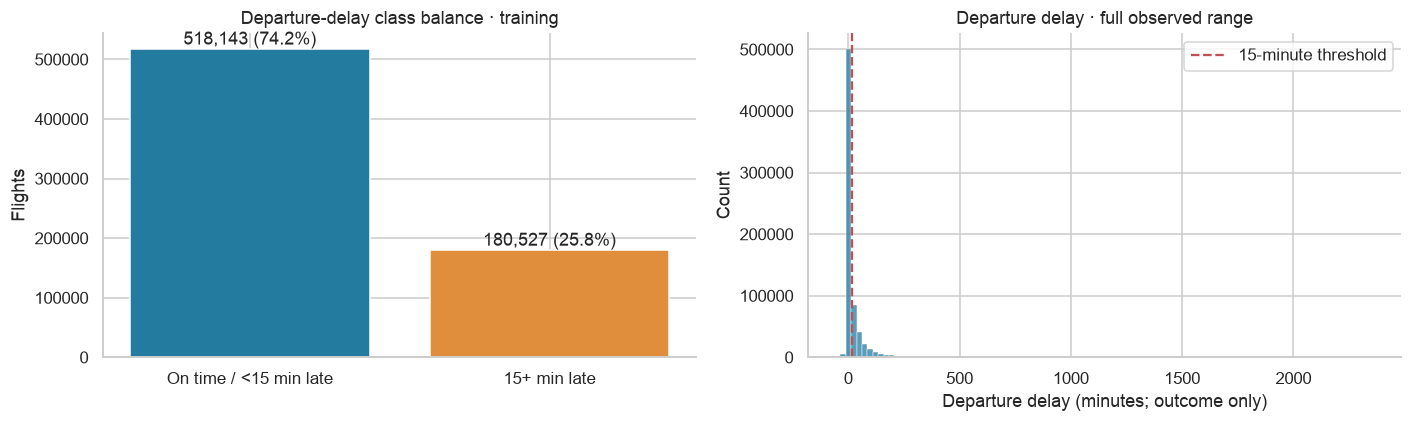

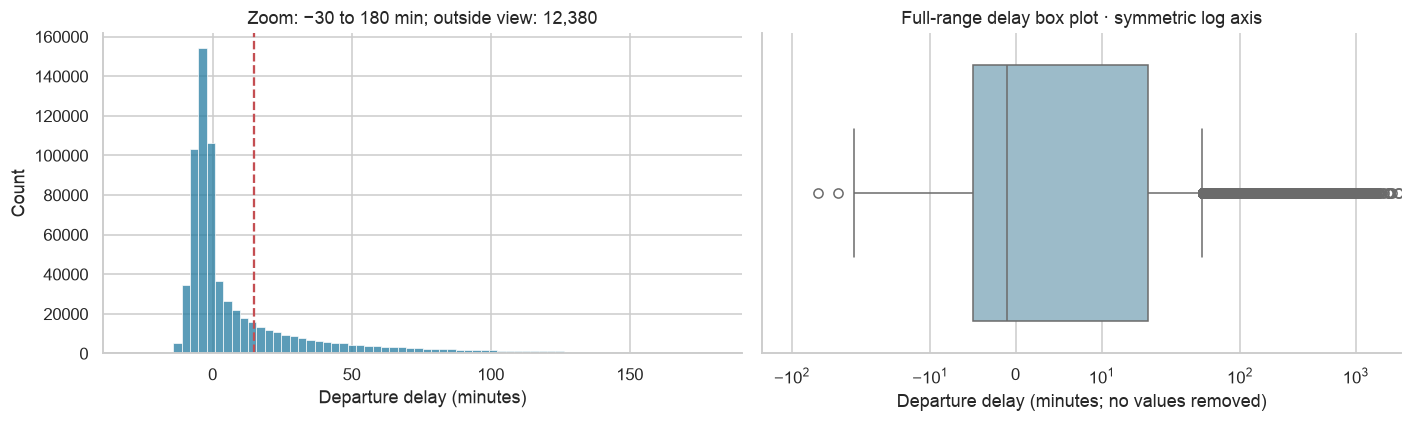

In [8]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
counts = train['target_label'].value_counts()
axes[0].bar(counts.index, counts.values, color=['#247BA0', '#E08D3C'])
for i, value in enumerate(counts.values):
    axes[0].text(i, value, f'{value:,} ({value / len(train):.1%})', ha='center', va='bottom')
axes[0].set(title='Departure-delay class balance · training', ylabel='Flights')
sns.histplot(data=train, x='departure_delay_minutes', bins=100, ax=axes[1])
axes[1].set(title='Departure delay · full observed range', xlabel='Departure delay (minutes; outcome only)')
axes[1].axvline(15, color='#C44E52', linestyle='--', label='15-minute threshold')
axes[1].legend()
show_plot()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
central = train['departure_delay_minutes'].between(-30, 180)
sns.histplot(data=train.loc[central], x='departure_delay_minutes', bins=70, ax=axes[0])
axes[0].axvline(15, color='#C44E52', linestyle='--')
axes[0].set(title=f'Zoom: −30 to 180 min; outside view: {(~central).sum():,}', xlabel='Departure delay (minutes)')
sns.boxplot(data=train, x='departure_delay_minutes', ax=axes[1], color='#95BED0')
axes[1].set_xscale('symlog', linthresh=15)
axes[1].set(title='Full-range delay box plot · symmetric log axis', xlabel='Departure delay (minutes; no values removed)')
show_plot()


                                count        mean         std   min     1%    25%    50%     75%     95%     99%     max
distance_miles               698670.0  758.785707  498.860156  67.0  106.0  404.0  666.0   985.0  1744.0  2165.0  4502.0
scheduled_duration_minutes   698670.0  138.538174   63.715659  37.0   54.0   91.0  126.0   166.0   272.0   316.0   624.0
scheduled_departure_minutes  698670.0  860.894763  290.559886  59.0  355.0  605.0  863.0  1116.0  1310.0  1374.0  1439.0
departure_delay_minutes      698670.0   17.131902   57.265011 -60.0  -11.0   -5.0   -1.0    16.0   101.0   233.0  2364.0


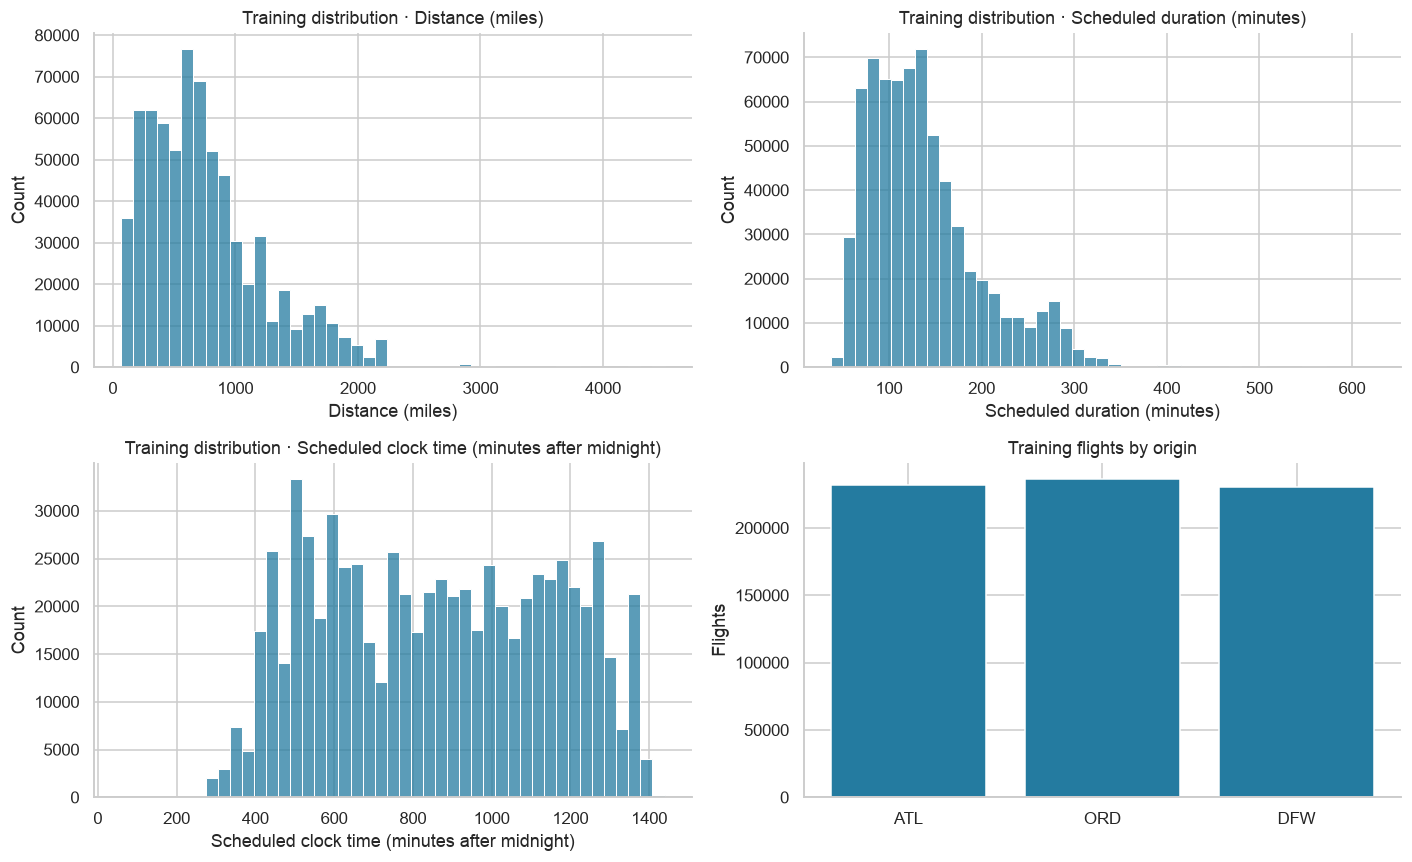

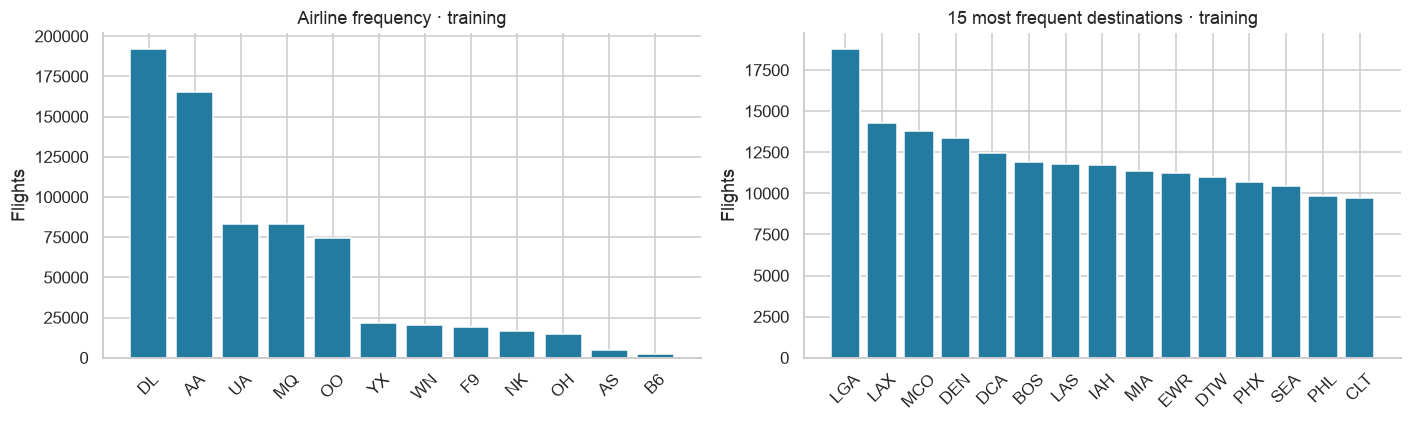

In [9]:
show_table(train[['distance_miles', 'scheduled_duration_minutes', 'scheduled_departure_minutes',
               'departure_delay_minutes']].describe(percentiles=[.01, .25, .5, .75, .95, .99]).T)
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for column, label, ax in zip(['distance_miles', 'scheduled_duration_minutes', 'scheduled_departure_minutes'],
                           ['Distance (miles)', 'Scheduled duration (minutes)', 'Scheduled clock time (minutes after midnight)'], axes.flat):
    sns.histplot(data=train, x=column, bins=45, ax=ax)
    ax.set(title=f'Training distribution · {label}', xlabel=label)
airport_counts = train['origin'].value_counts().reindex(ORIGINS)
axes[1, 1].bar(airport_counts.index, airport_counts.values)
axes[1, 1].set(title='Training flights by origin', ylabel='Flights')
show_plot()

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
for column, ax, title in [('airline', axes[0], 'Airline frequency'), ('destination', axes[1], '15 most frequent destinations')]:
    frequencies = train[column].value_counts().head(15)
    ax.bar(frequencies.index.astype(str), frequencies.values)
    ax.tick_params(axis='x', rotation=45)
    ax.set(title=title + ' · training', ylabel='Flights')
show_plot()


### Percentages and skewness

Report counts and percentages, then mean/median/skewness for appropriate numerical variables. Departure-delay statistics describe the outcome only.


In [10]:
for column in ['origin', 'airline', 'month', 'weekday']:
    frequency = pd.DataFrame({'n': train[column].value_counts(dropna=False),
                              'percent': train[column].value_counts(dropna=False, normalize=True).mul(100)})
    print(f'\n{column}: count and percentage distribution')
    show_table(frequency)



origin: count and percentage distribution
             n    percent
origin                   
ORD     236160  33.801365
ATL     231994   33.20509
DFW     230516  32.993545

airline: count and percentage distribution
              n    percent
airline                   
DL       192269  27.519287
AA       165387   23.67169
UA        83017  11.882148
MQ        82956  11.873417
OO        74528  10.667125
YX        21879   3.131521
WN        20069   2.872458
F9        19315   2.764538
NK        16580    2.37308
OH        15069   2.156812
AS         5027    0.71951
B6         2574   0.368414

month: count and percentage distribution
           n    percent
month                  
7      85870  12.290495
6      83824  11.997653
8      82833  11.855812
5      81336  11.641548
9      79728  11.411396
3      76878  11.003478
4      75908  10.864643
1      67425   9.650479
2      64868   9.284498

weekday: count and percentage distribution
                n    percent
weekday                   

In [11]:
skew_columns = ['distance_miles', 'scheduled_duration_minutes', 'departure_delay_minutes']
distribution_review = train[skew_columns].agg(['count', 'mean', 'median', 'std', 'min', 'max', 'skew']).T
show_table(distribution_review)
print('Departure delay is shown for outcome understanding only; X excludes it.')


                               count        mean  median         std   min     max      skew
distance_miles              698670.0  758.785707   666.0  498.860156  67.0  4502.0  1.510114
scheduled_duration_minutes  698670.0  138.538174   126.0   63.715659  37.0   624.0  1.458038
departure_delay_minutes     698670.0   17.131902    -1.0   57.265011 -60.0  2364.0  8.108279
Departure delay is shown for outcome understanding only; X excludes it.


Use the plots and counts to describe the observed training data. A frequent airline or airport is not necessarily a high-risk one; compare rates next.


## 2. Bivariate analysis

Compare group delay rates with counts, distributions by class, scatter plots and predictor correlations. These associations do not establish causation or predictive improvement.


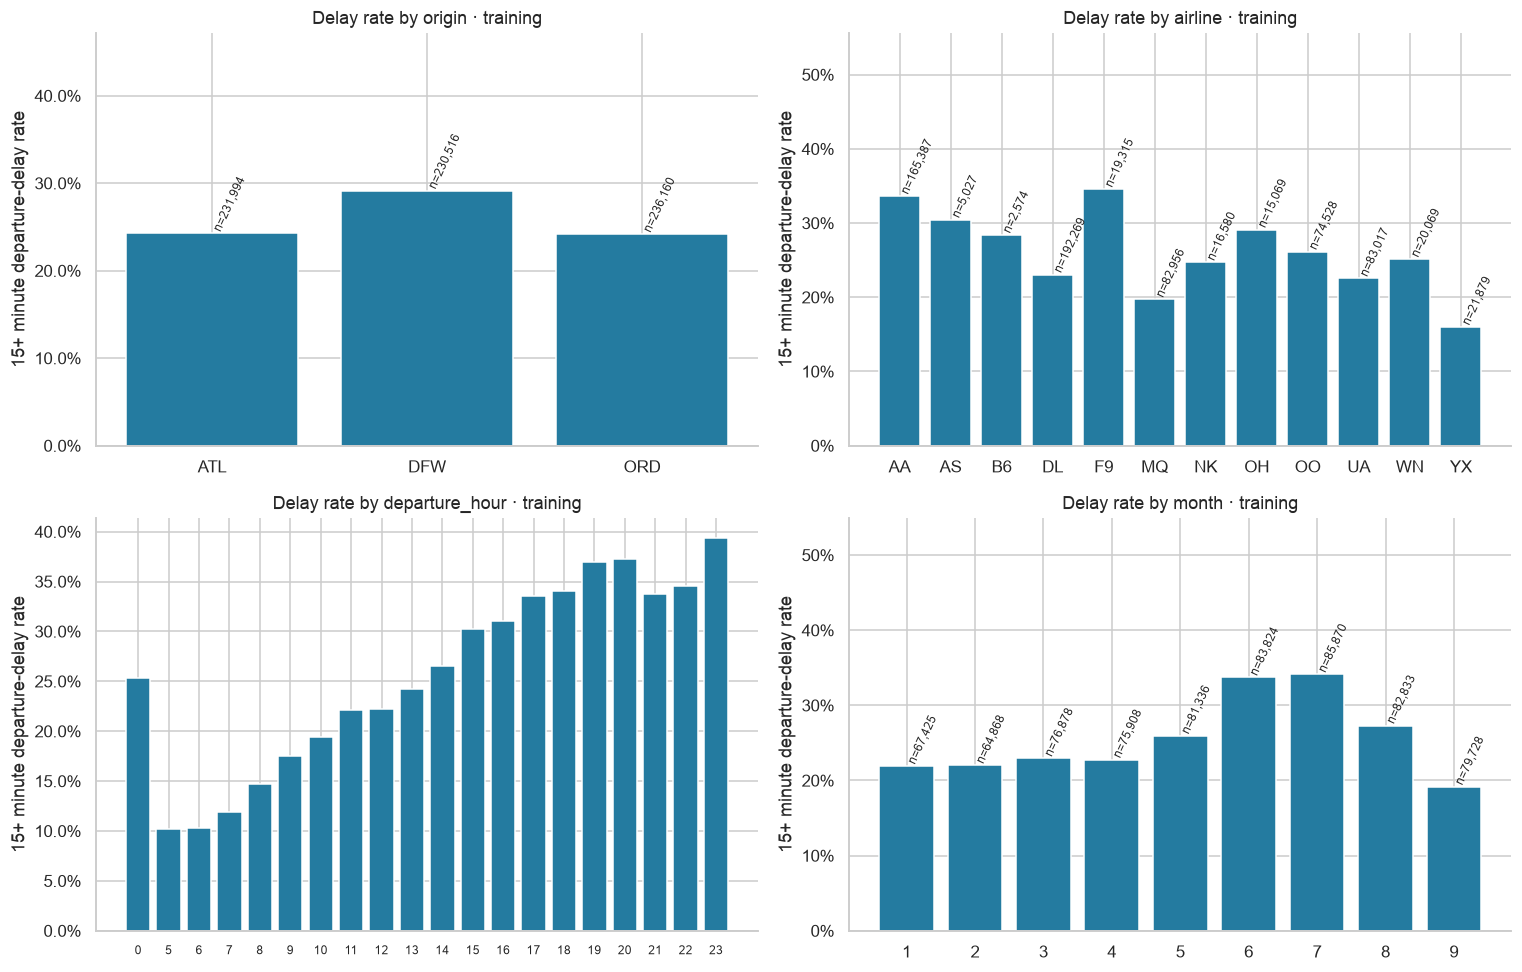

   airline       n  delayed  delay_rate
3       DL  192269    44340    0.230614
0       AA  165387    55637    0.336405
9       UA   83017    18711    0.225388
5       MQ   82956    16371    0.197346
8       OO   74528    19496    0.261593
11      YX   21879     3500    0.159971
10      WN   20069     5048    0.251532
4       F9   19315     6679    0.345793
6       NK   16580     4094    0.246924
7       OH   15069     4389     0.29126
1       AS    5027     1531    0.304555
2       B6    2574      731    0.283994


In [12]:
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
group_tables = {}
for group, ax in zip(['origin', 'airline', 'departure_hour', 'month'], axes.flat):
    table = rate_table(train, group)
    group_tables[group] = table
    ax.bar(table[group].astype(str), table['delay_rate'], color='#247BA0')
    ax.yaxis.set_major_formatter(PercentFormatter(1))
    ax.set(title=f'Delay rate by {group} · training', ylabel='15+ minute departure-delay rate')
    if len(table) <= 15:
        for i, row in table.reset_index(drop=True).iterrows():
            ax.text(i, row['delay_rate'], f'n={int(row["n"]):,}', rotation=65, ha='left', va='bottom', fontsize=8)
        ax.set_ylim(0, min(1, table['delay_rate'].max() * 1.55 + .02))
    else:
        ax.tick_params(axis='x', labelsize=8)
show_plot()
show_table(group_tables['airline'].sort_values('n', ascending=False))


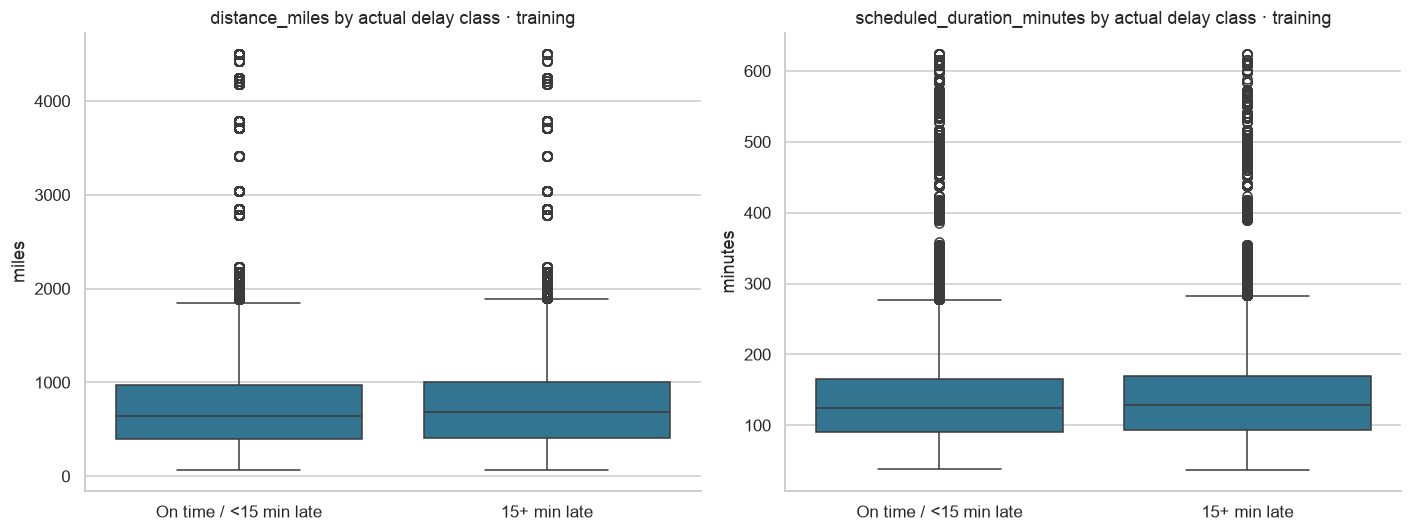

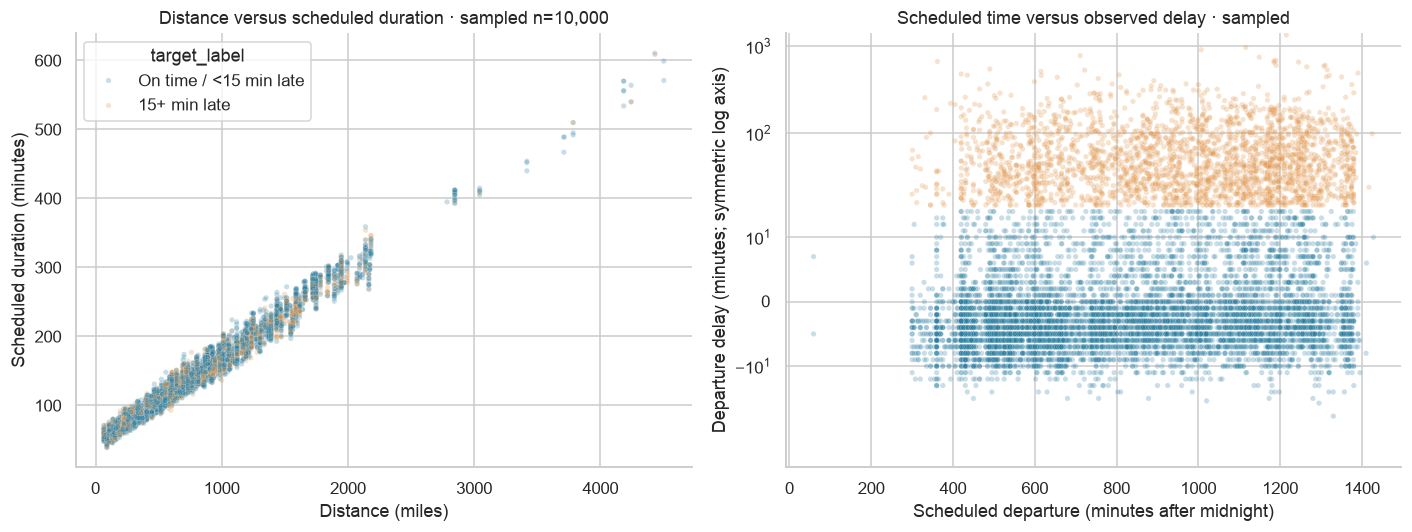

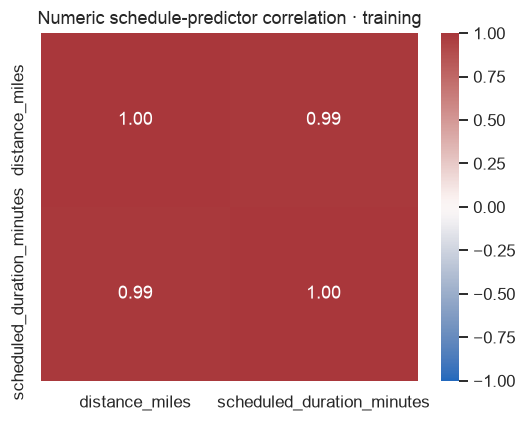

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for column, ax, units in [('distance_miles', axes[0], 'miles'),
                          ('scheduled_duration_minutes', axes[1], 'minutes')]:
    sns.boxplot(data=train, x='target_label', y=column, showfliers=True, ax=ax)
    ax.set(title=f'{column} by actual delay class · training', xlabel='', ylabel=units)
show_plot()

scatter = plot_sample(train)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.scatterplot(data=scatter, x='distance_miles', y='scheduled_duration_minutes',
                hue='target_label', alpha=.25, s=12, ax=axes[0])
axes[0].set(title=f'Distance versus scheduled duration · sampled n={len(scatter):,}',
            xlabel='Distance (miles)', ylabel='Scheduled duration (minutes)')
sns.scatterplot(data=scatter, x='scheduled_departure_minutes', y='departure_delay_minutes',
                hue='target_label', alpha=.25, s=12, legend=False, ax=axes[1])
axes[1].set_yscale('symlog', linthresh=15)
axes[1].set(title='Scheduled time versus observed delay · sampled',
            xlabel='Scheduled departure (minutes after midnight)', ylabel='Departure delay (minutes; symmetric log axis)')
show_plot()

correlations = train[['distance_miles', 'scheduled_duration_minutes']].corr()
fig, ax = plt.subplots(figsize=(5, 4))
sns.heatmap(correlations, annot=True, fmt='.2f', vmin=-1, vmax=1, cmap='vlag', ax=ax)
ax.set_title('Numeric schedule-predictor correlation · training')
show_plot()


## 3. Missing value treatment

Keep cancelled/unknown-label records as schedule context but exclude them from classification. Retain missing predictor rows; learn imputation from training data only.


                            missing_n  missing_fraction
departure_delay_minutes         13217          0.018549
departure_delay_15_source       13217          0.018549
airline                             0          0.000000
destination                         0          0.000000
scheduled_duration_minutes          0          0.000000
distance_miles                      0          0.000000
diverted                            0          0.000000


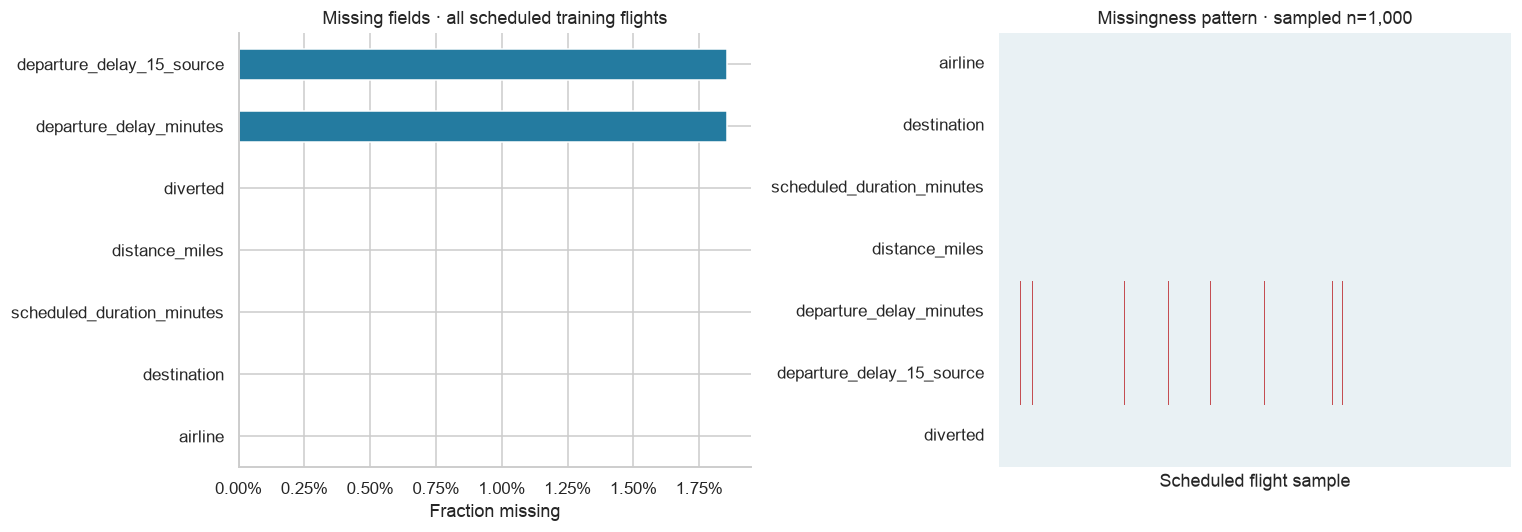

                                                 rows
2025 scheduled scope rows                      957315
2025 cancelled                                  18898
2025 noncancelled, unknown departure label          0
2025 eligible query flights                    938417
2025 eligible later-diverted flights retained    2750


In [14]:
missing_columns = ['airline', 'destination', 'scheduled_duration_minutes', 'distance_miles',
                   'departure_delay_minutes', 'departure_delay_15_source', 'diverted']
training_scheduled = flights.loc[flights['split'].eq('train')]
missing_table = pd.DataFrame({'missing_n': training_scheduled[missing_columns].isna().sum(),
                              'missing_fraction': training_scheduled[missing_columns].isna().mean()})
show_table(missing_table.sort_values('missing_fraction', ascending=False))
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
missing_table['missing_fraction'].sort_values().plot.barh(ax=axes[0])
axes[0].xaxis.set_major_formatter(PercentFormatter(1))
axes[0].set(title='Missing fields · all scheduled training flights', xlabel='Fraction missing')
missing_sample = plot_sample(training_scheduled, maximum=1_000)
sns.heatmap(missing_sample[missing_columns].isna().T, cbar=False, xticklabels=False,
            cmap=['#E9F1F4', '#C44E52'], ax=axes[1])
axes[1].set(title=f'Missingness pattern · sampled n={len(missing_sample):,}', xlabel='Scheduled flight sample')
show_plot()

# Describe exclusions in 2025 development only; no 2026 outcome exploration.
exclusion_counts = pd.Series({
    '2025 scheduled scope rows': int(development.sum()),
    '2025 cancelled': int((development & flights['cancelled'].eq(1)).sum()),
    '2025 noncancelled, unknown departure label': int((development & flights['cancelled'].eq(0) & flights['departure_delay_minutes'].isna()).sum()),
    '2025 eligible query flights': int((development & flights['query_eligible']).sum()),
    '2025 eligible later-diverted flights retained': int((development & flights['query_eligible'] & flights['diverted'].eq(1)).sum()),
})
show_table(exclusion_counts.to_frame('rows'))
assert exclusion_counts['2025 scheduled scope rows'] == (
    exclusion_counts['2025 cancelled'] + exclusion_counts['2025 noncancelled, unknown departure label']
    + exclusion_counts['2025 eligible query flights'])


## 4. Outlier treatment

Compare statistical flags, then apply physical-validity checks. Nonpositive distance/duration become missing with flags. Preserve legitimate early departures, severe delays and other valid extremes.


### Compare three diagnostic rules

Show IQR, mean ±3 SD and upper-99th-percentile bounds/counts on training predictors. A flagged value is not automatically an error. These rules do not cap values or delete flights.


In [15]:
def compare_outlier_rules(frame, columns):
    """Report training-only flags without changing the data."""
    rows = []
    for column in columns:
        values = pd.to_numeric(frame[column], errors='coerce').dropna()
        values = values[np.isfinite(values)]
        if values.empty:
            rows.append([column, 0, 'Unavailable: no finite values', *([np.nan] * 4)])
            continue
        q1, q3 = values.quantile([.25, .75])
        iqr, mean, sd = q3 - q1, values.mean(), values.std(ddof=0)
        rules = [('IQR: Q1-1.5IQR to Q3+1.5IQR', q1 - 1.5 * iqr, q3 + 1.5 * iqr),
                 ('Mean +/- 3 SD (ddof=0)', mean - 3 * sd, mean + 3 * sd),
                 ('Above 99th percentile only', -np.inf, values.quantile(.99))]
        for method, lower, upper in rules:
            flagged = (values < lower) | (values > upper)
            rows.append([column, len(values), method, lower if np.isfinite(lower) else np.nan,
                         upper, int(flagged.sum()), 100 * flagged.mean()])
    fields = ['variable', 'n', 'method', 'lower_bound', 'upper_bound', 'flagged_n', 'flagged_percent']
    return pd.DataFrame(rows, columns=fields) if rows else pd.DataFrame()


In [16]:
outlier_method_review = compare_outlier_rules(train, ['distance_miles', 'scheduled_duration_minutes'])
show_table(outlier_method_review, index=False)
print('No values were capped and no flights were removed by these statistical rules.')


                  variable      n                      method  lower_bound  upper_bound  flagged_n  flagged_percent
            distance_miles 698670 IQR: Q1-1.5IQR to Q3+1.5IQR  -467.500000  1856.500000      20787         2.975224
            distance_miles 698670      Mean +/- 3 SD (ddof=0)  -737.793689  2255.365103       2762         0.395323
            distance_miles 698670  Above 99th percentile only          NaN  2165.000000       6431         0.920463
scheduled_duration_minutes 698670 IQR: Q1-1.5IQR to Q3+1.5IQR   -21.500000   278.500000      27641         3.956231
scheduled_duration_minutes 698670      Mean +/- 3 SD (ddof=0)   -52.608667   329.685015       4093         0.585827
scheduled_duration_minutes 698670  Above 99th percentile only          NaN   316.000000       6827         0.977142
No values were capped and no flights were removed by these statistical rules.


                     variable                                rule  affected_all_context_and_study_rows  training_iqr_flag_count_diagnostic_only  capping_applied
0              distance_miles  nonpositive -> missing; retain row                                    0                                    20787            False
1  scheduled_duration_minutes  nonpositive -> missing; retain row                                    0                                    27641            False


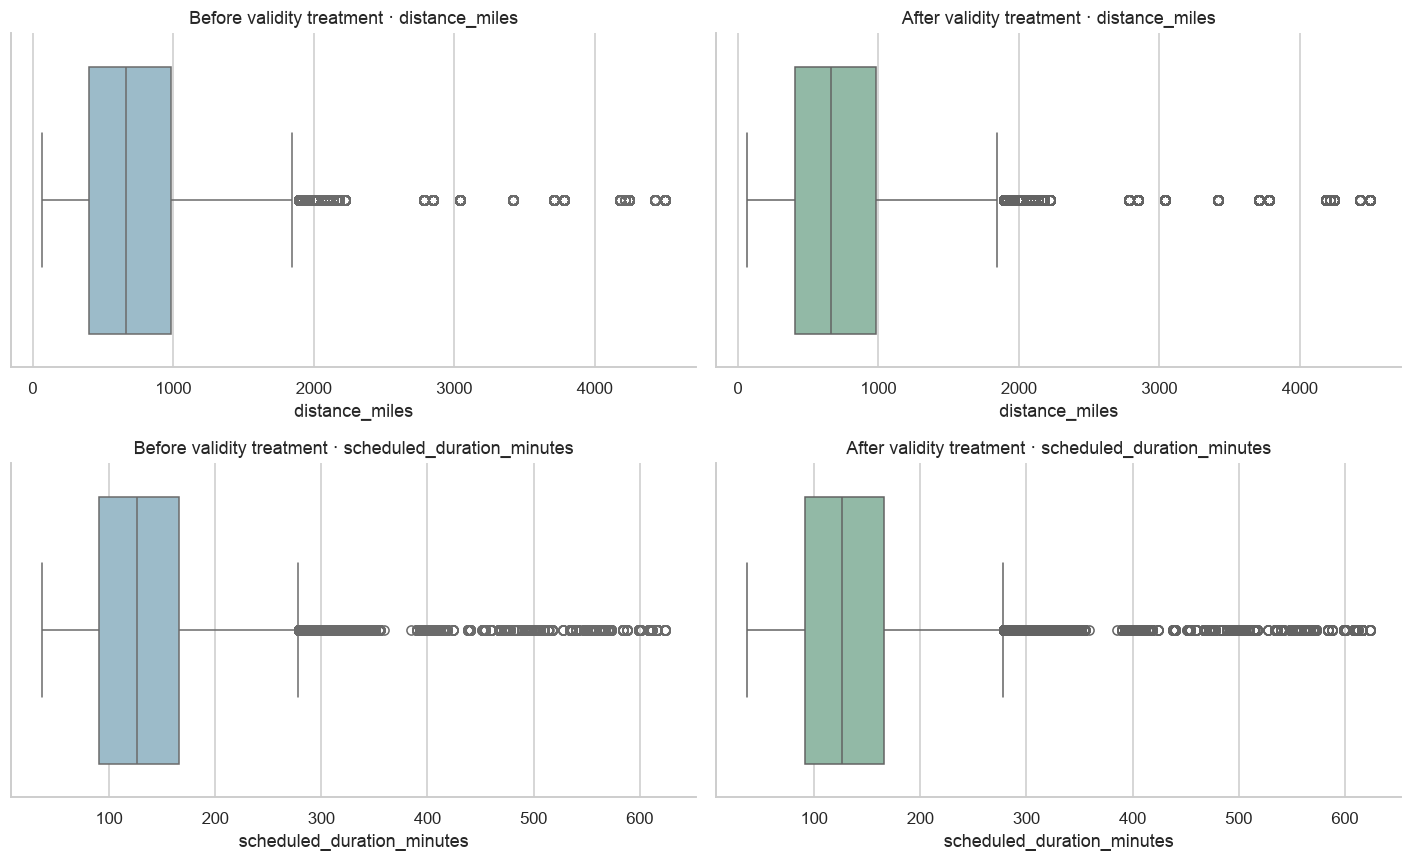

Treatment decision: no IQR-based row removal, no percentile capping, and no alteration of the label-defining departure delay. Review any nonzero invalid-value counts above before interpreting the findings.


In [17]:
iqr_counts = outlier_method_review.loc[outlier_method_review['method'].str.startswith('IQR')].set_index('variable')['flagged_n'].fillna(0)
treatment_log = []
for column in ['distance_miles', 'scheduled_duration_minutes']:
    invalid = flights[column].notna() & flights[column].le(0)
    flights[column + '_invalid'] = invalid.astype('int8')
    treatment_log.append({'variable': column, 'rule': 'nonpositive -> missing; retain row',
                          'affected_all_context_and_study_rows': int(invalid.sum()),
                          'training_iqr_flag_count_diagnostic_only': int(iqr_counts[column]),
                          'capping_applied': False})
    flights.loc[invalid, column] = np.nan
show_table(pd.DataFrame(treatment_log))

fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for row, column in enumerate(['distance_miles', 'scheduled_duration_minutes']):
    sns.boxplot(x=train[column], ax=axes[row, 0], color='#95BED0')
    sns.boxplot(x=flights.loc[train.index, column], ax=axes[row, 1], color='#8CBFA6')
    axes[row, 0].set(title=f'Before validity treatment · {column}', xlabel=column)
    axes[row, 1].set(title=f'After validity treatment · {column}', xlabel=column)
show_plot()
print('Treatment decision: no IQR-based row removal, no percentile capping, and no alteration of the label-defining departure delay. Review any nonzero invalid-value counts above before interpreting the findings.')


## 5. Variable creation

Create calendar fields, reporting time bands and cyclic clock and month coordinates. The target/cutoff were created earlier because the audit and bivariate analysis needed them.


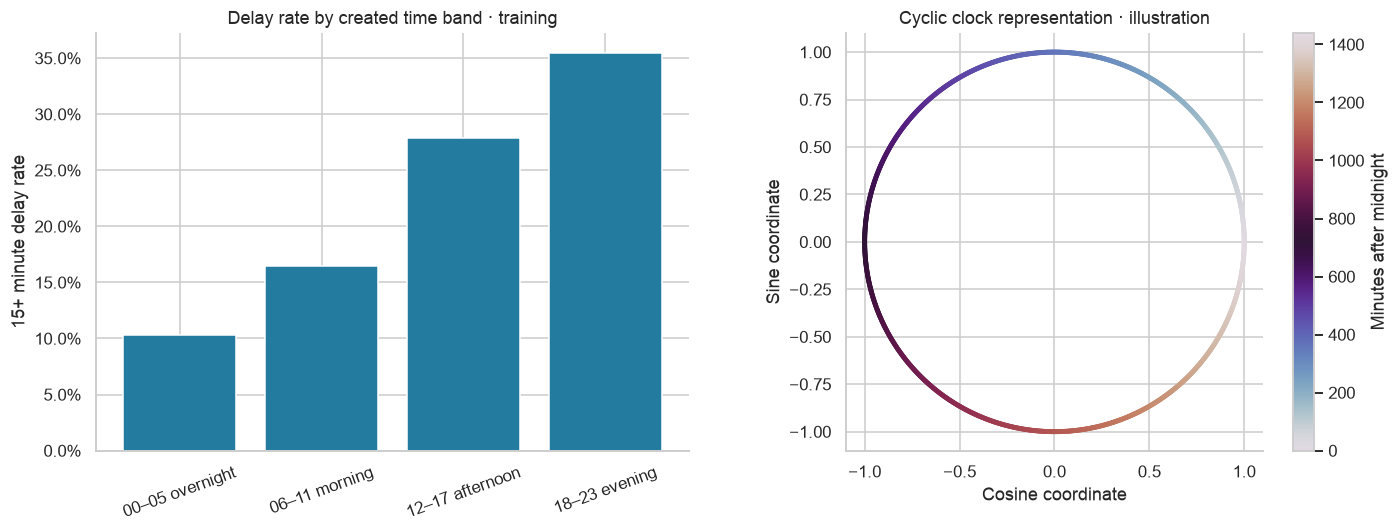

In [18]:
flights['month'] = flights['flight_date'].dt.month.astype('int8')
flights['weekday'] = flights['flight_date'].dt.dayofweek.astype('int8')
flights['departure_hour'] = (flights['scheduled_departure_minutes'] // 60).astype('int8')
flights['departure_time_band'] = pd.cut(flights['departure_hour'], bins=[-1, 5, 11, 17, 23],
    labels=['00–05 overnight', '06–11 morning', '12–17 afternoon', '18–23 evening']).astype('string')
angle = 2 * np.pi * flights['scheduled_departure_minutes'] / 1440
flights['departure_sin'] = np.sin(angle)
flights['departure_cos'] = np.cos(angle)
month_angle = 2 * np.pi * (flights['month'] - 1) / 12
flights['month_sin'] = np.sin(month_angle)
flights['month_cos'] = np.cos(month_angle)
train_after = flights.loc[train.index].copy()

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
band_rates = rate_table(train_after, 'departure_time_band')
axes[0].bar(band_rates['departure_time_band'], band_rates['delay_rate'])
axes[0].yaxis.set_major_formatter(PercentFormatter(1))
axes[0].tick_params(axis='x', rotation=20)
axes[0].set(title='Delay rate by created time band · training', ylabel='15+ minute delay rate')
clock_minutes = np.arange(1440)
clock_angle = 2 * np.pi * clock_minutes / 1440
points = axes[1].scatter(np.cos(clock_angle), np.sin(clock_angle), c=clock_minutes,
                          cmap='twilight', s=5)
axes[1].set(aspect='equal', title='Cyclic clock representation · illustration',
            xlabel='Cosine coordinate', ylabel='Sine coordinate')
fig.colorbar(points, ax=axes[1], label='Minutes after midnight')
show_plot()


## 6. Variable transformation

Inspect categorical conversion, log1p and train-fitted scaling. Final encoders/imputers/scalers belong inside each model's training pipeline.


### Assign dtype conversions

The reference's unassigned `astype()` does not change its column. Demonstrate an assigned conversion on five rows; weekday stays categorical; month uses fixed cyclic coordinates in the model.


In [19]:
category_example = train_after[['month', 'weekday']].head(5).copy()
print('Before conversion:')
show_table(category_example.dtypes)
for column in category_example.columns:
    category_example[column] = category_example[column].astype('string')
print('After assigned conversion:')
show_table(category_example.dtypes)
show_table(category_example, index=False)


Before conversion:
month      int8
weekday    int8
After assigned conversion:
month      string
weekday    string
month weekday
    1       2
    1       2
    1       3
    1       4
    1       5


### Original versus log1p distance

Check the domain, compare full-training skewness, and plot the same fixed-seed sample before/after. This is an illustration, not a new model feature or target transformation.


        original_distance  log1p_distance
153143              837.0        6.731018
153144              569.0        6.345636
153145              569.0        6.345636
153146              569.0        6.345636
153147              569.0        6.345636
   representation      n  skewness
original distance 698670  1.510114
   log1p distance 698670 -0.437825
Missing/invalid distances excluded from this illustration: 0


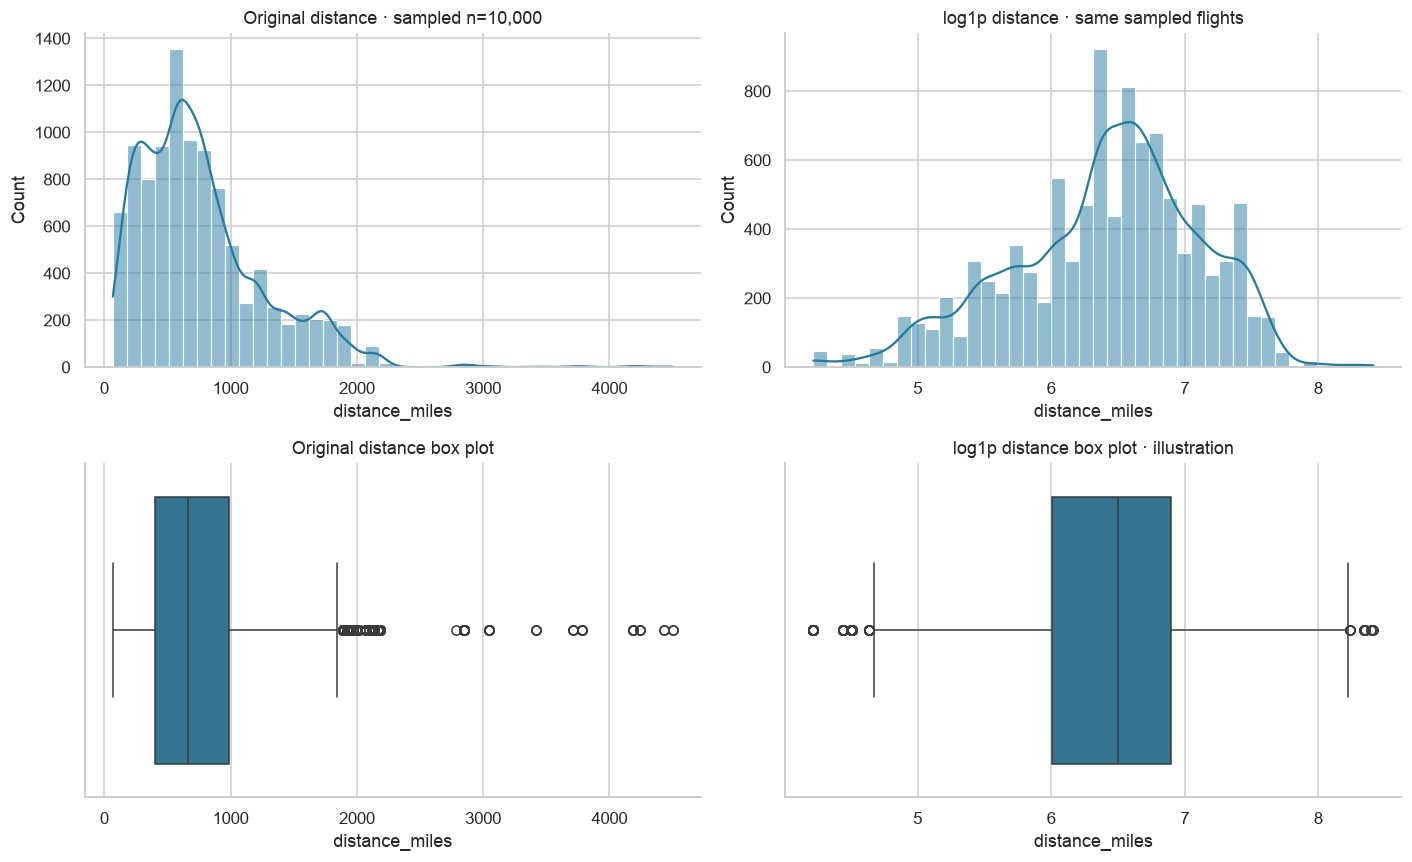

In [20]:
distance = train_after['distance_miles']
valid_distance = distance.notna() & np.isfinite(distance) & distance.ge(0)
distance_original = distance.loc[valid_distance]
distance_log = np.log1p(distance_original)
show_table(pd.DataFrame({'original_distance': distance_original, 'log1p_distance': distance_log}).head())
show_table(pd.DataFrame({'representation': ['original distance', 'log1p distance'],
                    'n': [len(distance_original), len(distance_log)],
                    'skewness': [distance_original.skew(), distance_log.skew()]}), index=False)
print('Missing/invalid distances excluded from this illustration:', int((~valid_distance).sum()))
if distance_original.nunique() > 1:
    sampled_original = distance_original.sample(n=min(10_000, len(distance_original)), random_state=SEED)
    sampled_log = np.log1p(sampled_original)
    fig, axes = plt.subplots(2, 2, figsize=(13, 8))
    sns.histplot(sampled_original, bins=40, kde=True, ax=axes[0, 0])
    sns.histplot(sampled_log, bins=40, kde=True, ax=axes[0, 1])
    sns.boxplot(x=sampled_original, ax=axes[1, 0])
    sns.boxplot(x=sampled_log, ax=axes[1, 1])
    axes[0, 0].set_title(f'Original distance · sampled n={len(sampled_original):,}')
    axes[0, 1].set_title('log1p distance · same sampled flights')
    axes[1, 0].set_title('Original distance box plot')
    axes[1, 1].set_title('log1p distance box plot · illustration')
    show_plot()
else:
    print('Insufficient variation for a distribution transformation illustration.')


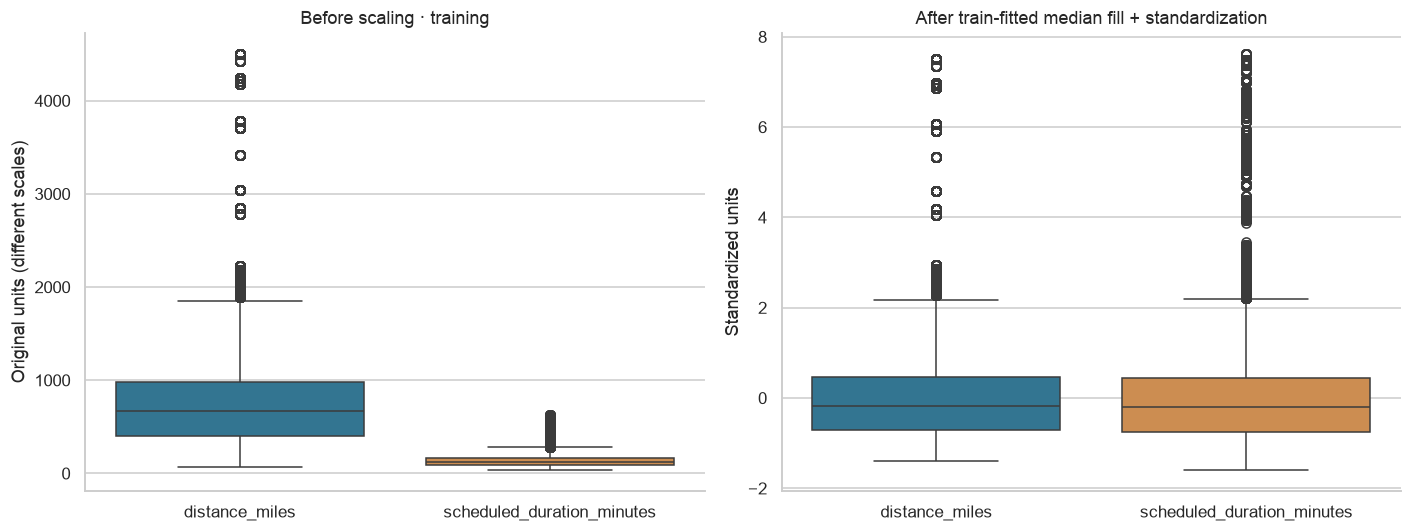

                                    mean       std
distance_miles             -2.082802e-17  1.000001
scheduled_duration_minutes -8.851910e-17  1.000001


In [21]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

preview_columns = ['distance_miles', 'scheduled_duration_minutes']
numeric_preview = Pipeline([('imputer', SimpleImputer(strategy='median', keep_empty_features=True)),
                            ('scaler', StandardScaler())])
scaled_preview = pd.DataFrame(numeric_preview.fit_transform(train_after[preview_columns]),
                              columns=preview_columns, index=train_after.index)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.boxplot(data=train_after[preview_columns], ax=axes[0])
axes[0].set(title='Before scaling · training', ylabel='Original units (different scales)')
sns.boxplot(data=scaled_preview, ax=axes[1])
axes[1].set(title='After train-fitted median fill + standardization', ylabel='Standardized units')
show_plot()
show_table(scaled_preview.agg(['mean', 'std']).T)


## Clean-data handoff

Save one schedule/context table with source IDs, timestamps and eligibility flags. It contains audit/outcome columns, so modelling must use an explicit feature allowlist.


In [22]:
import site
if site.ENABLE_USER_SITE:
    site.addsitedir(site.getusersitepackages())  # Make the newly installed engine visible without restarting.

assert flights['flight_id'].is_unique
assert flights.loc[flights['query_eligible'], 'delayed_departure'].notna().all()
assert (flights['prediction_cutoff_utc'] < flights['scheduled_departure_utc']).all()
assert not {'Tail_Number', 'tail_number', 'LateAircraftDelay'}.intersection(flights.columns)

cleaning_summary = {
    'completed_at_utc': datetime.now(timezone.utc).isoformat(),
    'source_files': source_log, 'parse_audit': parse_log,
    'population': population.reset_index().to_dict('records'),
    'exclusions': exclusion_counts.astype(int).to_dict(),
    'treatments': treatment_log, 'origin_timezones_from_raw': timezone_by_origin,
    'eda_period': CONFIG['split']['train_start'] + ' through ' + CONFIG['split']['train_end'],
    'split_definition': CONFIG['split'],
    'test_outcome_policy': CONFIG['evaluation_extension']['test_outcome_policy'],
    'outliers': 'valid extremes retained; no automatic capping or IQR row deletion',
    'availability_note': 'Historical simulation; weather/outcome delivery and archived schedule availability are assumptions.',
    'output': 'data/processed/flights_clean.parquet',
}
if WRITE_OUTPUTS:
    output = ROOT / 'data/processed/flights_clean.parquet'
    output.parent.mkdir(parents=True, exist_ok=True)
    flights.to_parquet(output, engine='pyarrow', index=False, compression='zstd')
    manifest_path = ROOT / 'reports/preparation_manifest.json'
    manifest_path.parent.mkdir(parents=True, exist_ok=True)
    manifest = json.loads(manifest_path.read_text()) if manifest_path.exists() else {}
    manifest['cleaning'] = cleaning_summary
    manifest.pop('feature_engineering', None)  # Rebuild notebook 02 after every fresh clean handoff.
    manifest_path.write_text(json.dumps(manifest, indent=2, default=str) + '\n')
    print(f'Saved {output.relative_to(ROOT)} ({len(flights):,} rows).')
    print('Next: review findings, then run 02_feature_engineering.ipynb.')
else:
    print('WRITE_OUTPUTS=False: nothing saved. Notebook 02 needs the clean handoff before running.')


Saved data/processed/flights_clean.parquet (1,339,044 rows).
Next: review findings, then run 02_feature_engineering.ipynb.


## Review

After running, interpret balance, missingness, extremes and treatment counts. ML evidence will answer the formal objectives.

[Objectives](../OBJECTIVES.md) · [Tableau plan](../tableau/WORKBOOK_PLAN.md) · [BTS fields](https://www.transtats.bts.gov/Fields.asp?gnoyr_VQ=FGJ) · [Training-only preprocessing](https://scikit-learn.org/stable/common_pitfalls.html)
